# Predikčná analýza: dopad bezpečnostného incidentu

Notebook implementuje a porovnáva 2 algoritmy strojového učenia na dátach VCDB. Nadväzuje na `priprava_dat.ipynb`, ktorý musí byť spustený ako prvý.

**Cieľ.** Hneď po odhalení incidentu odhadnúť, koľko záznamov pravdepodobne unikne. Organizácia tak vie včas rozhodnúť o rozsahu reakcie a pri hodnotení rizika vie odhadnúť dopad jednotlivých scenárov hrozby.

| | |
| --- | --- |
| **Vstup** | `data/processed/vcdb_clean.csv`, incidenty so známym počtom uniknutých záznamov |
| **Cieľ predikcie** | `dopad`: `nízky` (do 999 záznamov), `stredný` (do 99 999), `vysoký` (od 100 000) |
| **Vstupné znaky** | aktér, motív, spôsob útoku a jeho vektor, aktívum, typ dát, odvetvie, veľkosť a krajina obete, spôsob odhalenia |
| **Modely** | logistická regresia, LightGBM, triviálny model ako spodná hranica |
| **Výstup** | tabuľka metrík, `figures/3_f1_dopad.png`, `figures/4_matice_zamen_dopad.png`, `data/processed/vcdb_predikcie.csv`, `data/processed/model_dopad_vcdb.joblib` |

**Prevencia úniku informácií.** Vstupom nie je počet záznamov ani nič, čo sa dozvieme až po vyšetrení. Vynechávame popis incidentu, lebo často priamo uvádza počet dotknutých osôb, ďalej čas odhalenia, stav úniku dát a spôsob, akým bol incident vybraný do databázy.

In [1]:
import time
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    log_loss,
    mean_absolute_error,
    precision_recall_fscore_support,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline

DATA_PATH = Path("data/processed/vcdb_clean.csv")
PREDICTIONS_PATH = Path("data/processed/vcdb_predikcie.csv")
MODEL_PATH = Path("data/processed/model_dopad_vcdb.joblib")
FIGURES_DIR = Path("figures")
LABELS = ["nízky", "stredný", "vysoký"]
HIGH = LABELS.index("vysoký")
SEED = 42

clean = pd.read_csv(DATA_PATH, low_memory=False)
data = clean[clean["dopad"].notna()].reset_index(drop=True)
data["target"] = pd.Categorical(data["dopad"], categories=LABELS, ordered=True).codes
assert data["target"].between(0, 2).all()
print(f"Incidenty spolu: {len(clean)}, so známym dopadom: {len(data)}")
display(data["dopad"].value_counts().reindex(LABELS).to_frame("počet"))

Incidenty spolu: 9961, so známym dopadom: 5097


,počet
dopad,
nízky,2431
stredný,1783
vysoký,883


## 1. Rozdelenie dát

Mnohé incidenty pochádzajú z toho istého článku alebo zoznamu a sú si takmer rovnaké. Keby boli zároveň v tréningu aj v teste, model by si ich zapamätal a výsledky by boli príliš optimistické. Preto delíme podľa stĺpca `skupina`: všetky incidenty z jedného zdroja sú vždy v tej istej časti.

**Hromadné zdroje idú vždy do tréningu.** Prvý pokus o rozdelenie ukázal, že jediný zoznam incidentov rezortu U.S. Department of Veterans Affairs má 687 incidentov so známym dopadom, takmer všetky s nízkym dopadom. Keď padol do testu, tvoril polovicu testu a zvyšok testu mal iba 3 incidenty s nízkym dopadom. Výsledky tak hovorili viac o jednom zozname než o modeli. Incidenty zo zdrojov s aspoň 20 incidentmi sa preto používajú iba na učenie a testuje sa na bežných incidentoch, ktoré zodpovedajú novým jednotlivým incidentom.

`StratifiedGroupKFold` rozdelí bežné incidenty na 4 časti so zachovaným pomerom tried. Jedna časť (približne 25 %) je testovacia a použije sa iba raz na záver. Parametre sa vyberajú 5-násobnou krížovou validáciou na zvyšku, opäť so zachovaním skupín. Hromadné zdroje sú v každom kroku iba v učiacej časti.

In [2]:
bulk = data[data["hromadny_zdroj"]].reset_index(drop=True)
regular = data[~data["hromadny_zdroj"]].reset_index(drop=True)

outer = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
train_index, test_index = next(outer.split(regular, regular["target"], regular["skupina"]))
train = pd.concat([regular.iloc[train_index], bulk], ignore_index=True)
test = regular.iloc[test_index].reset_index(drop=True)
assert not set(train["skupina"]) & set(test["skupina"])
assert not test["hromadny_zdroj"].any()

split_summary = pd.DataFrame({
    "tréning, bežné %": regular.iloc[train_index]["dopad"].value_counts(normalize=True).reindex(LABELS).mul(100).round(1),
    "tréning, hromadné %": bulk["dopad"].value_counts(normalize=True).reindex(LABELS).mul(100).round(1),
    "test %": test["dopad"].value_counts(normalize=True).reindex(LABELS).mul(100).round(1),
})
split_summary.loc["počet incidentov"] = [len(train_index), len(bulk), len(test)]
display(split_summary)

y_train, y_test = train["target"].to_numpy(), test["target"].to_numpy()
is_regular = ~train["hromadny_zdroj"].to_numpy()
regular_positions = np.flatnonzero(is_regular)
bulk_positions = np.flatnonzero(~is_regular)
inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
inner_folds = [
    (np.concatenate([regular_positions[fit], bulk_positions]), regular_positions[validate])
    for fit, validate in inner.split(regular_positions, y_train[is_regular], train["skupina"].to_numpy()[is_regular])
]

,"tréning, bežné %","tréning, hromadné %",test %
dopad,,,
nízky,40.0,83.9,40.1
stredný,39.1,15.7,39.1
vysoký,20.9,0.5,20.8
počet incidentov,3157.0,888.0,1052.0


## 2. Príprava znakov

| Typ stĺpca | Stĺpce | Spracovanie |
| --- | --- | --- |
| Viac hodnôt naraz | spôsob útoku, vektor, aktér, aktívum, typ dát, motív, spôsob odhalenia | binárny príznak pre každú hodnotu, ktorá sa vyskytne aspoň v 5 incidentoch |
| Kategória | odvetvie, veľkosť organizácie, krajina, cielenosť, vzor útoku | one-hot kódovanie, zriedkavé hodnoty sa zlúčia |
| Áno a nie | príznaky aktéra, spôsobu útoku, aktíva, dotknutej integrity a dostupnosti, ransomvér | priamo ako 0 a 1 |

Slovník hodnôt sa vždy učí iba z tréningových dát. Funkcie na prípravu znakov sú v module `vcdb_model.py`, aby sa uložený model dal použiť aj mimo notebooku.

In [3]:
from vcdb_model import CATEGORICAL, FLAGS, MULTI, make_features

print("Stĺpce s viacerými hodnotami:", MULTI)
print("Kategórie:", CATEGORICAL)
print("Príznaky áno a nie:", len(FLAGS))
example = make_features().fit(train)
print("Počet znakov:", example.transform(train.head(1)).shape[1])

Stĺpce s viacerými hodnotami: ['akcia_variety', 'akcia_vektory', 'aktor_variety', 'aktivum_variety', 'typy_dat', 'motiv', 'sposob_odhalenia']
Kategórie: ['odvetvie', 'velkost_organizacie', 'krajina_skupina', 'cielenost', 'vzor_utoku']
Príznaky áno a nie: 21
Počet znakov: 232


## 3. Implementované algoritmy a výber parametrov

**Logistická regresia** je lineárny model. Každý znak má pre každú triedu jednu váhu, preto je rýchla a dobre vysvetliteľná.

**LightGBM** je gradient boosting nad rozhodovacími stromami. Stromy sa stavajú postupne a každý opravuje chyby predchádzajúcich, takže model zachytí aj kombinácie znakov, napríklad hacking cez webovú aplikáciu v kombinácii s osobnými údajmi.

Oba modely používajú `class_weight="balanced"`, aby málo početná trieda `vysoký` nebola prehliadnutá. Parametre sa vyberajú podľa **macro F1** v krížovej validácii.

In [4]:
def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", labels=[0, 1, 2], zero_division=0)


def make_logreg(C):
    return LogisticRegression(C=C, class_weight="balanced", max_iter=3000, random_state=SEED)


def make_lightgbm(num_leaves, n_estimators):
    return lgb.LGBMClassifier(
        objective="multiclass",
        class_weight="balanced",
        n_estimators=n_estimators,
        learning_rate=0.05,
        num_leaves=num_leaves,
        min_child_samples=20,
        colsample_bytree=0.5,
        subsample=0.8,
        subsample_freq=1,
        reg_lambda=1.0,
        random_state=SEED,
        deterministic=True,
        force_row_wise=True,
        n_jobs=4,
        verbosity=-1,
    )


def out_of_fold(model):
    """Predikcie pre každý bežný tréningový incident z modelu, ktorý ho pri učení nevidel."""
    probabilities = np.zeros((len(train), 3))
    for fit_index, predict_index in inner_folds:
        pipeline = Pipeline([("features", make_features()), ("model", clone(model))])
        pipeline.fit(train.iloc[fit_index], y_train[fit_index])
        probabilities[predict_index] = pipeline.predict_proba(train.iloc[predict_index])
    return probabilities[is_regular]


y_regular = y_train[is_regular]


candidates = {f"LR C={C}": make_logreg(C) for C in [0.1, 0.3, 1, 3]}
candidates.update({
    f"LightGBM listy={leaves} stromy={trees}": make_lightgbm(leaves, trees)
    for leaves in [15, 31] for trees in [100, 250, 500]
})

oof, rows = {}, []
for name, model in candidates.items():
    started = time.perf_counter()
    oof[name] = out_of_fold(model)
    rows.append({
        "model": name,
        "macro F1": macro_f1(y_regular, oof[name].argmax(axis=1)),
        "čas (s)": time.perf_counter() - started,
    })

tuning = pd.DataFrame(rows).round(4)
display(tuning)
best_logreg = tuning[tuning["model"].str.startswith("LR")].sort_values("macro F1").iloc[-1]["model"]
best_lightgbm = tuning[tuning["model"].str.startswith("LightGBM")].sort_values("macro F1").iloc[-1]["model"]
print("Najlepšia logistická regresia:", best_logreg)
print("Najlepší LightGBM:", best_lightgbm)

,model,macro F1,čas (s)
0,LR C=0.1,0.6224,0.6712
1,LR C=0.3,0.6249,0.6916
2,LR C=1,0.6241,0.8249
3,LR C=3,0.6142,0.9488
4,LightGBM listy=15 stromy=100,0.6263,0.9571
5,LightGBM listy=15 stromy=250,0.6304,1.6001
6,LightGBM listy=15 stromy=500,0.6241,2.5630
7,LightGBM listy=31 stromy=100,0.6357,1.1489
8,LightGBM listy=31 stromy=250,0.6268,2.1430
9,LightGBM listy=31 stromy=500,0.6192,3.7920


Najlepšia logistická regresia: LR C=0.3
Najlepší LightGBM: LightGBM listy=31 stromy=100


## 4. Kalibrácia pravdepodobností

Preskriptívna analýza potrebuje **pravdivé pravdepodobnosti** tried, nielen najpravdepodobnejšiu triedu. Váhy tried `balanced` ich zámerne skresľujú v prospech zriedkavých tried. Kalibrátor, multinomická logistická regresia nad logaritmami pravdepodobností, sa preto učí na predikciách z krížovej validácie, teda na incidentoch, ktoré model pri učení nevidel.

In [5]:
def fit_calibrator(probabilities, y):
    return LogisticRegression(C=1e4, max_iter=5000).fit(np.log(np.clip(probabilities, 1e-6, 1)), y)


def calibrate(calibrator, probabilities):
    return calibrator.predict_proba(np.log(np.clip(probabilities, 1e-6, 1)))


calibrators = {name: fit_calibrator(oof[name], y_regular) for name in [best_logreg, best_lightgbm]}

## 5. Záverečné učenie a vyhodnotenie na testovacích dátach

Modely sa naučia na celej tréningovej časti a testovacia časť sa použije iba raz.

In [6]:
final_models = {
    "Triviálny model": DummyClassifier(strategy="prior"),
    "Logistická regresia": candidates[best_logreg],
    "LightGBM": candidates[best_lightgbm],
}
calibrator_for = {"Logistická regresia": calibrators[best_logreg], "LightGBM": calibrators[best_lightgbm]}

pipelines, probabilities, predictions, fit_seconds = {}, {}, {}, {}
for name, model in final_models.items():
    started = time.perf_counter()
    pipelines[name] = Pipeline([("features", make_features()), ("model", clone(model))]).fit(train, y_train)
    fit_seconds[name] = time.perf_counter() - started
    raw = pipelines[name].predict_proba(test)
    predictions[name] = raw.argmax(axis=1) if name != "Triviálny model" else np.zeros(len(test), dtype=int)
    probabilities[name] = calibrate(calibrator_for[name], raw) if name in calibrator_for else raw

### Použité metriky

| Metrika | Čo meria |
| --- | --- |
| **Macro F1** | hlavná metrika, priemer F1 všetkých tried, každá trieda má rovnakú váhu |
| **Accuracy** | podiel správnych predikcií, pri nevyvážených triedach môže klamať |
| **MAE poradia** | priemerná vzdialenosť tried, `nízky` = 0 až `vysoký` = 2, menej je lepšie |
| **Recall a precision `vysoký`** | koľko incidentov s vysokým dopadom model zachytí a ako často je jeho poplach správny |
| **Log loss** | kvalita kalibrovaných pravdepodobností, ktoré použije preskriptívna analýza, menej je lepšie |

In [7]:
def evaluate(y_true, y_pred, proba):
    precision, recall, _, _ = precision_recall_fscore_support(y_true, y_pred, labels=[HIGH], zero_division=0)
    return {
        "Macro F1": macro_f1(y_true, y_pred),
        "Accuracy": accuracy_score(y_true, y_pred),
        "MAE poradia": mean_absolute_error(y_true, y_pred),
        "Recall vysoký": recall[0],
        "Precision vysoký": precision[0],
        "Log loss": log_loss(y_true, proba, labels=[0, 1, 2]),
    }


metrics = pd.DataFrame({
    name: evaluate(y_test, predictions[name], probabilities[name]) for name in final_models
}).T
metrics["Tréning (s)"] = pd.Series(fit_seconds)
metrics.round(3)

,Macro F1,Accuracy,MAE poradia,Recall vysoký,Precision vysoký,Log loss,Tréning (s)
Triviálny model,0.191,0.401,0.807,0.000,0.000,1.079,0.077
Logistická regresia,0.656,0.652,0.399,0.785,0.597,0.759,0.127
LightGBM,0.660,0.659,0.392,0.767,0.585,0.735,0.230


In [8]:
per_class = pd.concat({
    name: pd.DataFrame(
        precision_recall_fscore_support(y_test, predictions[name], labels=[0, 1, 2], zero_division=0)[:3],
        index=["precision", "recall", "F1"],
        columns=LABELS,
    ).T
    for name in ["Logistická regresia", "LightGBM"]
})
display(per_class.round(3))

# Spoľahlivosť rozdielu: bootstrap po skupinách, lebo incidenty z jedného zdroja nie sú nezávislé
rng = np.random.default_rng(SEED)
groups = test["skupina"].to_numpy()
unique_groups = np.unique(groups)
members = {group: np.flatnonzero(groups == group) for group in unique_groups}


def high_recall(y_true, y_pred):
    return (y_pred[y_true == HIGH] == HIGH).mean()


differences = {"macro F1": [], "recall vysoký": [], "log loss": []}
for _ in range(500):
    sample = np.concatenate([members[group] for group in rng.choice(unique_groups, len(unique_groups))])
    y_sample = y_test[sample]
    lgbm, logreg = predictions["LightGBM"][sample], predictions["Logistická regresia"][sample]
    differences["macro F1"].append(macro_f1(y_sample, lgbm) - macro_f1(y_sample, logreg))
    differences["recall vysoký"].append(high_recall(y_sample, lgbm) - high_recall(y_sample, logreg))
    differences["log loss"].append(
        log_loss(y_sample, probabilities["LightGBM"][sample], labels=[0, 1, 2])
        - log_loss(y_sample, probabilities["Logistická regresia"][sample], labels=[0, 1, 2])
    )

for metric, values in differences.items():
    low, high = np.percentile(values, [2.5, 97.5])
    print(f"Rozdiel {metric} (LightGBM mínus logistická regresia): {np.mean(values):.4f}, 95 % interval [{low:.4f}, {high:.4f}]")

precision  recall     F1
Logistická regresia nízky        0.759   0.573  0.653
                    stredný      0.611   0.662  0.636
                    vysoký       0.597   0.785  0.679
LightGBM            nízky        0.790   0.581  0.669
                    stredný      0.615   0.681  0.647
                    vysoký       0.585   0.767  0.664

Rozdiel macro F1 (LightGBM mínus logistická regresia): 0.0042, 95 % interval [-0.0158, 0.0244]
Rozdiel recall vysoký (LightGBM mínus logistická regresia): -0.0190, 95 % interval [-0.0619, 0.0199]
Rozdiel log loss (LightGBM mínus logistická regresia): -0.0245, 95 % interval [-0.0389, -0.0097]


## 6. Vizualizácie výsledkov

In [9]:
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
MODEL_COLORS = {"Logistická regresia": "#2a78d6", "LightGBM": "#eb6834"}

plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 10,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "text.color": INK,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "savefig.dpi": 160,
    "savefig.bbox": "tight",
    "savefig.facecolor": SURFACE,
})
FIGURES_DIR.mkdir(exist_ok=True)

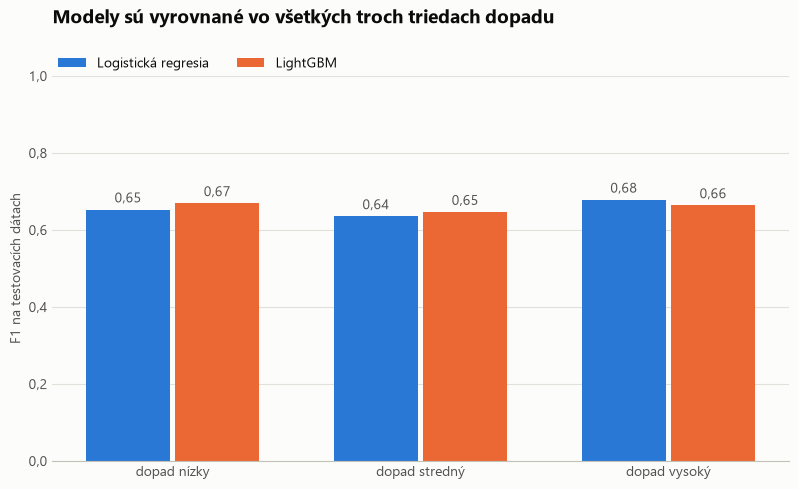

In [10]:
fig, ax = plt.subplots(figsize=(9.5, 5))
positions = np.arange(len(LABELS))
width = 0.36

for offset, name in zip((-width / 2, width / 2), MODEL_COLORS):
    values = per_class.loc[name, "F1"].reindex(LABELS).to_numpy()
    bars = ax.bar(positions + offset, values, width - 0.02, color=MODEL_COLORS[name], label=name)
    ax.bar_label(bars, labels=[f"{value:.2f}".replace(".", ",") for value in values], padding=3, color=INK_SECONDARY)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.set_xticks(positions, [f"dopad {label}" for label in LABELS])
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda value, _: f"{value:.1f}".replace(".", ","))
ax.set_ylabel("F1 na testovacích dátach")
ax.set_title("Modely sú vyrovnané vo všetkých troch triedach dopadu", loc="left", fontsize=14, fontweight="bold", pad=38)
ax.legend(ncols=2, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), borderaxespad=0)

fig.savefig(FIGURES_DIR / "3_f1_dopad.png")
plt.show()

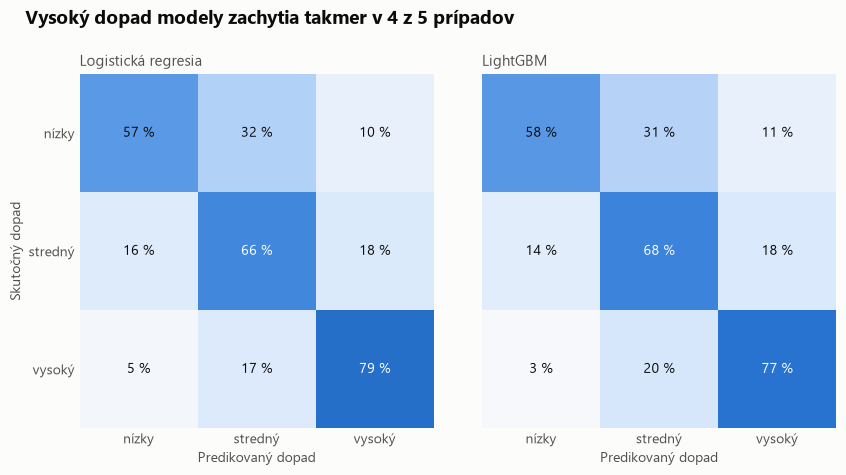

In [11]:
blues = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#cde2fb", "#6da7ec", "#2a78d6", "#104281"])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True, gridspec_kw={"wspace": 0.08})

for ax, name in zip(axes, MODEL_COLORS):
    matrix = confusion_matrix(y_test, predictions[name], labels=[0, 1, 2], normalize="true")
    ax.imshow(matrix, cmap=blues, vmin=0, vmax=1)
    for row in range(3):
        for column in range(3):
            value = matrix[row, column]
            ax.text(column, row, f"{value * 100:.0f} %", ha="center", va="center",
                    color="#ffffff" if value >= 0.6 else INK)
    ax.set_title(name, loc="left", fontsize=11, color=INK_SECONDARY)
    ax.set_xticks(range(3), LABELS)
    ax.set_yticks(range(3), LABELS)
    ax.set_xlabel("Predikovaný dopad")
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)

axes[0].set_ylabel("Skutočný dopad")
fig.suptitle("Vysoký dopad modely zachytia takmer v 4 z 5 prípadov", x=0.08, y=1.02, ha="left", fontsize=14, fontweight="bold")
fig.savefig(FIGURES_DIR / "4_matice_zamen_dopad.png")
plt.show()

## 7. Čo modely považujú za dôležité

In [12]:
logreg_pipeline = pipelines["Logistická regresia"]
names = logreg_pipeline.named_steps["features"].named_steps["columns"].get_feature_names_out()
coefficients = logreg_pipeline.named_steps["model"].coef_
top_words = pd.DataFrame({
    label: [name.replace("__", ": ") for name in names[np.argsort(coefficients[index])[::-1][:10]]]
    for index, label in enumerate(LABELS)
})
print("Znaky s najvyššou váhou v logistickej regresii podľa triedy:")
display(top_words)

lightgbm_pipeline = pipelines["LightGBM"]
lgbm_names = lightgbm_pipeline.named_steps["features"].named_steps["columns"].get_feature_names_out()
gain = pd.Series(lightgbm_pipeline.named_steps["model"].booster_.feature_importance(importance_type="gain"), index=lgbm_names)
gain.index = [name.replace("__", ": ") for name in gain.index]
print("Znaky s najvyšším prínosom v LightGBM:")
gain.sort_values(ascending=False).head(12).round(0).to_frame("gain")

Znaky s najvyššou váhou v logistickej regresii podľa triedy:


,nízky,stredný,vysoký
0,typy_dat: Unknown,akcia_variety: error:Malfunction,aktivum_variety: M - Tapes
1,aktivum_variety: M - Documents,motiv: Ideology,categorical: odvetvie_Informácie
2,akcia_variety: error:Gaffe,aktor_variety: external:Activist,akcia_variety: hacking:Forced browsing
3,aktor_variety: internal:Cashier,akcia_vektory: hacking:Command shell,akcia_variety: physical:Bypassed controls
4,akcia_vektory: misuse:Physical access,aktivum_variety: U - Desktop or laptop,aktivum_variety: S - POS controller
5,aktor_variety: internal:End-user,aktivum_variety: M - Flash drive,aktor_variety: internal:System admin
6,aktivum_variety: M - Payment card,akcia_variety: misuse:Email misuse,aktivum_variety: M - Disk drive
7,flags: akcia_misuse,akcia_vektory: malware:Remote injection,aktivum_variety: M - Disk media
8,akcia_variety: error:Misdelivery,categorical: krajina_skupina_US,akcia_variety: error:Misconfiguration
9,aktor_variety: internal:Doctor or nurse,categorical: odvetvie_Veľkoobchod,typy_dat: Virtual currency


Znaky s najvyšším prínosom v LightGBM:


,gain
typy_dat: Unknown,2894.0
typy_dat: Medical,2693.0
flags: aktivum_server,2401.0
categorical: odvetvie_Zdravotníctvo,1786.0
typy_dat: Personal,1732.0
categorical: odvetvie_Verejná správa,1553.0
flags: akcia_misuse,1487.0
aktivum_variety: M - Documents,1412.0
categorical: krajina_skupina_US,1223.0
flags: aktor_internal,1071.0


## 8. Uloženie modelu a predikcií

Pre preskriptívnu analýzu sa ukladajú kalibrované pravdepodobnosti oboch modelov pre testovacie incidenty. Do prevádzky sa ukladá model, ktorý mal v krížovej validácii vyššie macro F1. Vyberá sa podľa krížovej validácie, nie podľa testu, aby test zostal nezávislý.

In [13]:
cv_score = tuning.set_index("model")["macro F1"]
chosen = "LightGBM" if cv_score[best_lightgbm] >= cv_score[best_logreg] else "Logistická regresia"
print("Model pre preskriptívnu analýzu a prevádzku:", chosen)

output = test[["zaznam_id", "skupina", "odvetvie", "velkost_organizacie", "vzor_utoku", "pocet_zaznamov", "dopad"]].copy()
for name in ["Logistická regresia", "LightGBM"]:
    prefix = "lr" if name == "Logistická regresia" else "lgbm"
    for index, label in enumerate(LABELS):
        output[f"p_{prefix}_{label}"] = probabilities[name][:, index]
output["model_zvoleny"] = chosen
output.to_csv(PREDICTIONS_PATH, index=False, encoding="utf-8")

# Prevádzkový model sa učí na všetkých incidentoch so známym dopadom, kalibrátor zostáva z krížovej validácie
production = Pipeline([("features", make_features()), ("model", clone(final_models[chosen]))]).fit(data, data["target"])
joblib.dump({"pipeline": production, "calibrator": calibrator_for[chosen], "labels": LABELS, "model": chosen}, MODEL_PATH)
print(f"Uložené: {PREDICTIONS_PATH} ({len(output)} riadkov), {MODEL_PATH}")

Model pre preskriptívnu analýzu a prevádzku: LightGBM


Uložené: data\processed\vcdb_predikcie.csv (1052 riadkov), data\processed\model_dopad_vcdb.joblib


## 9. Zhrnutie a odporúčanie

Výsledky platia pre testovaciu množinu 1 052 bežných incidentov, ktorých zdroje model pri učení nevidel. Modely sa učili na 3 157 bežných incidentoch a 888 incidentoch z hromadných zdrojov.

| Metrika | Triviálny model | Logistická regresia | LightGBM |
| --- | ---: | ---: | ---: |
| Macro F1 | 0,191 | 0,656 | 0,660 |
| Accuracy | 0,401 | 0,652 | 0,659 |
| MAE poradia | 0,807 | 0,399 | 0,392 |
| Recall `vysoký` | 0,000 | 0,785 | 0,767 |
| Precision `vysoký` | 0,000 | 0,597 | 0,585 |
| Log loss | 1,079 | 0,759 | 0,735 |

**Vyhodnotenie:**

- Oba modely jasne prekonali triviálny model. Aktér, spôsob útoku, aktívum, typ dát a odvetvie teda nesú užitočnú informáciu o dopade incidentu.
- V triedení sú modely vyrovnané. Rozdiel macro F1 je 0,004 v prospech LightGBM s 95 % intervalom [-0,016; 0,024] a rozdiel recallu triedy `vysoký` je -0,019 s intervalom [-0,062; 0,020]. Oba intervaly obsahujú nulu.
- Spoľahlivý rozdiel je v kvalite pravdepodobností. LightGBM má nižší log loss o 0,025 s intervalom [-0,039; -0,010].
- Výsledok na teste (macro F1 0,66) zodpovedá krížovej validácii (0,64), takže nie je náhodne priaznivý.
- Vysoký dopad predikujú najmä stratené zálohovacie pásky a disky, odvetvie informácií, prístup k nechráneným adresám webu (`Forced browsing`), chybná konfigurácia a správcovia systémov. Nízky dopad predikujú omylom doručené zásielky, papierové dokumenty a zneužitie prístupu bežnými zamestnancami.

**Odporúčanie: LightGBM** pre preskriptívnu analýzu, lebo jeho pravdepodobnosti sú spoľahlivejšie a preskriptívna analýza z nich priamo počíta očakávané straty. Bol vybraný aj v krížovej validácii. Logistická regresia je rovnako dobrá na samotné triedenie a ľahšie sa vysvetľuje.

**Rozdelenie dát.** Prvý pokus náhodne zaradil do testu celý zoznam 687 incidentov rezortu VA. Macro F1 vtedy vyšlo 0,80, no bolo skreslené jedným zoznamom s takmer výlučne nízkym dopadom. Preto sú hromadné zdroje iba v tréningu.

**Obmedzenia:**

- Precision triedy `vysoký` je približne 0,59, takže zhruba 4 z 10 poplachov sú zbytočné. Asi 31 % incidentov s nízkym dopadom model zaradí do stredného.
- Dopad je meraný počtom záznamov, nie finančnou stratou.
- Dataset obsahuje iba verejne známe incidenty, prevažne z USA.
- Kalibrátor sa učil na predikciách z krížovej validácie, prevádzkový model na všetkých dátach. Jeho pravdepodobnosti môžu byť preto mierne odlišné od vyhodnotených.
- Prehľadané boli len malé mriežky parametrov.